# SIN 393 – Projeto: Classificação de tumores cerebrais em ressonância magnética (MRI)
Classificação de imagens em 4 classes (`glioma_tumor`, `meningioma_tumor`, `pituitary_tumor`, `normal`) com CNNs do torchvision.

**Pergunta experimental:** qual o impacto da arquitetura (ResNet-50 vs. EfficientNet-B0) e do data augmentation no desempenho?

**Dataset:** versão *limpa* do Brain Tumor Classification (MRI), da qual **removemos previamente imagens duplicadas e muito semelhantes utilizando o [difPy](https://difpy.app/)** (para reduzir vazamento de dados entre treino e teste).

**Fluxo:** setup → dataset → divisão treino/val/teste → augmentation → modelos → treino → avaliação no teste → análise qualitativa.
Rode as células de cima para baixo e ajuste apenas `DATA_DIR`.

## 1. Setup

In [13]:
import os, random, copy, time
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, accuracy_score,
                             precision_recall_fscore_support)
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)  # No Colab: Ambiente de execução > Alterar tipo > GPU T4

Device: cuda


## 2. Dataset – explorar a estrutura
Ajuste `DATA_DIR` para a pasta que **contém diretamente as pastas de classes** (uma pasta por classe: `glioma_tumor`, `meningioma_tumor`, `normal`, `pituitary_tumor`).
Se o dataset estiver em `.zip` no Drive, descomente as linhas de `unzip` para extrair no disco local do Colab (leitura bem mais rápida que direto do Drive).

In [14]:
from google.colab import drive
drive.mount('/content/drive')

# Opção A: ler direto do Drive (mais lento)
# DATA_DIR = '/content/drive/My Drive/BrainTumorDatasetLimpo/'

# Opção B (recomendada): extrair o zip no disco local do Colab
!unzip -q "/content/drive/My Drive/BrainTumorDataset.zip" -d /content/brain2
DATA_DIR = '/content/brain2/'     # ajuste: pasta que contém as pastas das classes

for root, dirs, files in os.walk(DATA_DIR):
    depth = root[len(DATA_DIR):].count(os.sep)
    if depth <= 2:
        print('  '*depth + os.path.basename(root), '->', len(files), 'arquivos')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/brain2/pituitary_tumor/P_706.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
 -> 0 arquivos
normal -> 296 arquivos
pituitary_tumor -> 831 arquivos
meningioma_tumor -> 809 arquivos
glioma_tumor -> 885 arquivos


## 3. Divisão hold-out estratificada (treino / validação / teste)
- 70% / 15% / 15%, com `train_test_split` **estratificado** e **semente fixa**.
- A divisão é feita sobre os índices, em duas etapas (o `train_test_split` só separa em duas partes).
- **Teste:** usado apenas na avaliação final. **Validação:** escolhe o melhor checkpoint.

**Sobre vazamento de dados:** duplicatas e imagens muito semelhantes já foram removidas do dataset antes desta etapa. Como o dataset não traz ID de paciente, fatias diferentes do mesmo paciente ainda podem cair em conjuntos distintos. Citar isso como limitação no artigo.

In [15]:
base = ImageFolder(DATA_DIR)           # sem transforms: só lista caminhos e rótulos
paths   = [p for p, _ in base.samples]
labels  = np.array([y for _, y in base.samples])
class_names = base.classes
num_classes = len(class_names)
print('Classes:', class_names)
print('Total de imagens:', len(paths))

idx = np.arange(len(paths))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx   = train_test_split(temp_idx, test_size=0.50, stratify=labels[temp_idx], random_state=SEED)

for nome, ii in [('Treino', train_idx), ('Validação', val_idx), ('Teste', test_idx)]:
    cont = np.bincount(labels[ii], minlength=num_classes)
    print(f'{nome:10s} {len(ii):5d}', dict(zip(class_names, cont.tolist())))

Classes: ['glioma_tumor', 'meningioma_tumor', 'normal', 'pituitary_tumor']
Total de imagens: 2821
Treino      1974 {'glioma_tumor': 619, 'meningioma_tumor': 566, 'normal': 207, 'pituitary_tumor': 582}
Validação    423 {'glioma_tumor': 133, 'meningioma_tumor': 121, 'normal': 45, 'pituitary_tumor': 124}
Teste        424 {'glioma_tumor': 133, 'meningioma_tumor': 122, 'normal': 44, 'pituitary_tumor': 125}


## 4. Transforms e data augmentation
- **Todos os conjuntos:** resize 224×224 e normalização do ImageNet (o mesmo usado no pré-treino dos modelos). As imagens são em tons de cinza; `.convert('RGB')` replica o canal para as 3 entradas esperadas pelas CNNs.
- **Augmentation (só no treino), pensado para MRI:**
  - *Flip horizontal e rotação pequena (±10°):* simulam pequenas diferenças de posicionamento do paciente. **Sem flip vertical:** o cérebro tem orientação anatômica fixa.
  - *RandomResizedCrop (≥80%):* variação de escala/enquadramento sem cortar fora o tumor.
  - *Brilho/contraste leves:* variação de intensidade entre exames. **Sem saturação/matiz:** a imagem é em tons de cinza.

In [16]:
IMG_SIZE = 224
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # estatísticas do ImageNet

train_tf_aug = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
# Sem augmentation (para o experimento de comparação)
train_tf_plain = eval_tf

class PathDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.transform(img), int(self.labels[i])

def make_loaders(train_transform, batch_size=32, num_workers=2):
    ds_tr = PathDataset([paths[i] for i in train_idx], labels[train_idx], train_transform)
    ds_va = PathDataset([paths[i] for i in val_idx],   labels[val_idx],   eval_tf)
    ds_te = PathDataset([paths[i] for i in test_idx],  labels[test_idx],  eval_tf)
    g = torch.Generator().manual_seed(SEED)
    return (DataLoader(ds_tr, batch_size, shuffle=True, num_workers=num_workers, generator=g),
            DataLoader(ds_va, batch_size, shuffle=False, num_workers=num_workers),
            DataLoader(ds_te, batch_size, shuffle=False, num_workers=num_workers),
            ds_te)

## 5. Visualizar o efeito do augmentation

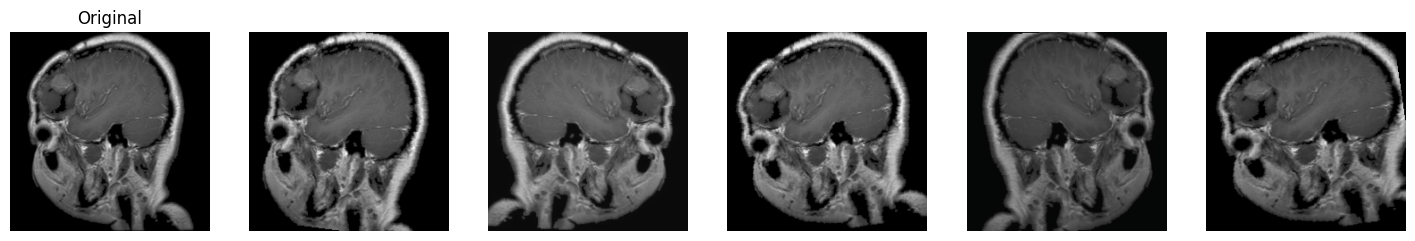

In [17]:
img = Image.open(paths[train_idx[0]]).convert('RGB')
fig, axs = plt.subplots(1, 6, figsize=(18, 3))
axs[0].imshow(img.resize((IMG_SIZE, IMG_SIZE))); axs[0].set_title('Original')
inv = lambda t: (t.permute(1,2,0).numpy() * std + mean).clip(0,1)
for a in axs[1:]:
    a.imshow(inv(train_tf_aug(img)))
for a in axs: a.axis('off')
plt.show()

## 6. Modelos (torchvision)
- **ResNet-50:** baseline clássico, com conexões residuais (~25M de parâmetros).
- **EfficientNet-B0:** arquitetura leve e eficiente (~5M de parâmetros).

Ambos com **transfer learning** (pesos do ImageNet): com poucos milhares de imagens, isso converge melhor que treinar do zero. A última camada é trocada para `num_classes` e a rede inteira é ajustada (fine-tuning).

In [18]:
from torchvision.models import ResNet50_Weights, EfficientNet_B0_Weights

def get_model(name, num_classes, pretrained=True):
    if name == 'resnet50':
        m = models.resnet50(weights=ResNet50_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    else:
        raise ValueError(name)
    return m.to(device)

## 7. Treinamento
- Perda `CrossEntropyLoss`; otimizador **`AdamW`** com `lr=1e-4` (taxa baixa para fine-tuning) e `weight_decay=1e-2` (decaimento de pesos desacoplado do gradiente). Hiperparâmetros **não foram otimizados**.
- **Early stopping:** o treino para quando a **acurácia de validação** não melhora por `patience` épocas seguidas (melhora = aumento maior que `min_delta`). `EPOCHS` passa a ser apenas o limite máximo.
- A cada época guardamos os pesos com a **melhor acurácia de validação** e os restauramos no final. Assim, o teste não participa de nenhuma decisão.

In [19]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot_loss = correct = n = 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot_loss += loss.item() * x.size(0)
            correct  += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return tot_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=30, lr=1e-4, weight_decay=1e-2,
        patience=5, min_delta=0.0, tag='model'):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {'tr_loss':[], 'va_loss':[], 'tr_acc':[], 'va_acc':[]}
    best_acc, best_state, best_ep, wait = 0, None, 0, 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(hist, [tl, vl, ta, va]): hist[k].append(v)
        if va > best_acc + min_delta:          # melhorou na VALIDAÇÃO: guarda o checkpoint
            best_acc, best_state, best_ep, wait = va, copy.deepcopy(model.state_dict()), ep, 0
        else:
            wait += 1
        print(f'[{tag}] ep {ep:02d} | tr_loss {tl:.4f} tr_acc {ta:.4f} | va_loss {vl:.4f} va_acc {va:.4f} | {time.time()-t0:.0f}s')
        if wait >= patience:                   # early stopping
            print(f'[{tag}] Early stopping na época {ep}: sem melhora há {patience} épocas '
                  f'(melhor va_acc {best_acc:.4f} na época {best_ep})')
            break
    model.load_state_dict(best_state)
    torch.save(best_state, f'{tag}.pth')
    hist['best_epoch'] = best_ep
    return model, hist

results = {}   # guarda modelos e históricos de cada experimento

## 8. Experimentos
Configurações sugeridas (2 arquiteturas × com/sem augmentation = 4 execuções).
Pergunta experimental: *"Qual o impacto do data augmentation em cada arquitetura, e qual arquitetura se sai melhor?"*

Dica: teste primeiro com `EPOCHS = 2` para ver se tudo roda; depois use `EPOCHS = 30` (limite máximo) e deixe o early stopping decidir quando parar.

In [20]:
EPOCHS = 30
PATIENCE = 5

experiments = [
    ('resnet50',        True),
    ('resnet50',        False),
    ('efficientnet_b0', True),
    ('efficientnet_b0', False),
]

for arch, use_aug in experiments:
    tag = f"{arch}_{'aug' if use_aug else 'noaug'}"
    set_seed()
    tr_l, va_l, te_l, te_ds = make_loaders(train_tf_aug if use_aug else train_tf_plain)
    model = get_model(arch, num_classes, pretrained=True)
    model, hist = fit(model, tr_l, va_l, epochs=EPOCHS, patience=PATIENCE, tag=tag)
    results[tag] = dict(model=model, hist=hist, test_loader=te_l, test_ds=te_ds)

[resnet50_aug] ep 01 | tr_loss 0.7744 tr_acc 0.7178 | va_loss 0.5166 va_acc 0.8014 | 23s
[resnet50_aug] ep 02 | tr_loss 0.3013 tr_acc 0.8896 | va_loss 0.2117 va_acc 0.9291 | 24s
[resnet50_aug] ep 03 | tr_loss 0.2000 tr_acc 0.9326 | va_loss 0.1934 va_acc 0.9220 | 24s
[resnet50_aug] ep 04 | tr_loss 0.1565 tr_acc 0.9453 | va_loss 0.1822 va_acc 0.9456 | 23s
[resnet50_aug] ep 05 | tr_loss 0.1014 tr_acc 0.9640 | va_loss 0.1760 va_acc 0.9338 | 23s
[resnet50_aug] ep 06 | tr_loss 0.0734 tr_acc 0.9757 | va_loss 0.1709 va_acc 0.9362 | 24s
[resnet50_aug] ep 07 | tr_loss 0.0819 tr_acc 0.9696 | va_loss 0.1585 va_acc 0.9527 | 23s
[resnet50_aug] ep 08 | tr_loss 0.0504 tr_acc 0.9858 | va_loss 0.1247 va_acc 0.9622 | 23s
[resnet50_aug] ep 09 | tr_loss 0.0576 tr_acc 0.9828 | va_loss 0.1571 va_acc 0.9433 | 23s
[resnet50_aug] ep 10 | tr_loss 0.0478 tr_acc 0.9848 | va_loss 0.1481 va_acc 0.9504 | 23s
[resnet50_aug] ep 11 | tr_loss 0.0433 tr_acc 0.9889 | va_loss 0.0844 va_acc 0.9693 | 23s
[resnet50_aug] ep 12 

## 9. Curvas de validação
Servem para checar convergência e sinais de overfitting (loss de validação subindo enquanto a de treino cai).

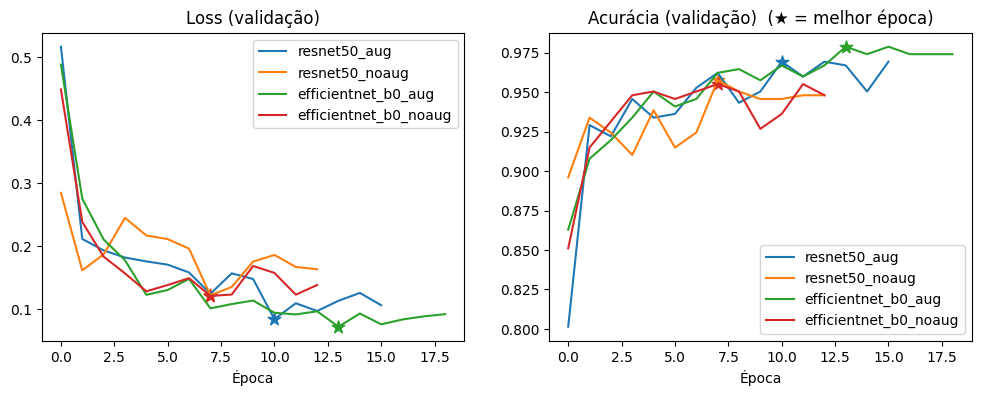

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for tag, r in results.items():
    l0, = axs[0].plot(r['hist']['va_loss'], label=tag)
    l1, = axs[1].plot(r['hist']['va_acc'], label=tag)
    b = r['hist']['best_epoch'] - 1          # época do melhor checkpoint (early stopping)
    axs[0].scatter(b, r['hist']['va_loss'][b], color=l0.get_color(), marker='*', s=90)
    axs[1].scatter(b, r['hist']['va_acc'][b],  color=l1.get_color(), marker='*', s=90)
axs[0].set_title('Loss (validação)'); axs[1].set_title('Acurácia (validação)  (★ = melhor época)')
for a in axs: a.set_xlabel('Época'); a.legend()
plt.show()

## 10. Avaliação final no conjunto de TESTE
Métricas: acurácia, precisão, recall e F1, com agregação **macro** (todas as classes com o mesmo peso; sensível à classe minoritária) e **weighted** (ponderada pelo nº de exemplos).

In [22]:
@torch.no_grad()
def predict(model, loader):
    model.eval(); yt, yp = [], []
    for x, y in loader:
        yp += model(x.to(device)).argmax(1).cpu().tolist(); yt += y.tolist()
    return np.array(yt), np.array(yp)

summary = []
for tag, r in results.items():
    yt, yp = predict(r['model'], r['test_loader'])
    r['yt'], r['yp'] = yt, yp
    print('='*60, '\n', tag)
    print(classification_report(yt, yp, target_names=class_names, digits=4))
    row = {'modelo': tag, 'acc': accuracy_score(yt, yp)}
    for avg in ['macro', 'weighted']:
        p, rc, f1, _ = precision_recall_fscore_support(yt, yp, average=avg, zero_division=0)
        row.update({f'prec_{avg}': p, f'rec_{avg}': rc, f'f1_{avg}': f1})
    summary.append(row)

import pandas as pd
df = pd.DataFrame(summary).set_index('modelo').round(4)
df

 resnet50_aug
                  precision    recall  f1-score   support

    glioma_tumor     0.9685    0.9248    0.9462       133
meningioma_tumor     0.9147    0.9672    0.9402       122
          normal     0.9565    1.0000    0.9778        44
 pituitary_tumor     0.9918    0.9680    0.9798       125

        accuracy                         0.9575       424
       macro avg     0.9579    0.9650    0.9610       424
    weighted avg     0.9587    0.9575    0.9576       424

 resnet50_noaug
                  precision    recall  f1-score   support

    glioma_tumor     0.9683    0.9173    0.9421       133
meningioma_tumor     0.9070    0.9590    0.9323       122
          normal     0.9778    1.0000    0.9888        44
 pituitary_tumor     0.9919    0.9840    0.9880       125

        accuracy                         0.9575       424
       macro avg     0.9612    0.9651    0.9628       424
    weighted avg     0.9586    0.9575    0.9576       424

 efficientnet_b0_aug
               

,acc,prec_macro,rec_macro,f1_macro,prec_weighted,rec_weighted,f1_weighted
modelo,,,,,,,
resnet50_aug,0.9575,0.9579,0.9650,0.9610,0.9587,0.9575,0.9576
resnet50_noaug,0.9575,0.9612,0.9651,0.9628,0.9586,0.9575,0.9576
efficientnet_b0_aug,0.9646,0.9703,0.9708,0.9705,0.9647,0.9646,0.9646
efficientnet_b0_noaug,0.9410,0.9467,0.9471,0.9469,0.9409,0.9410,0.9409


### Matrizes de confusão

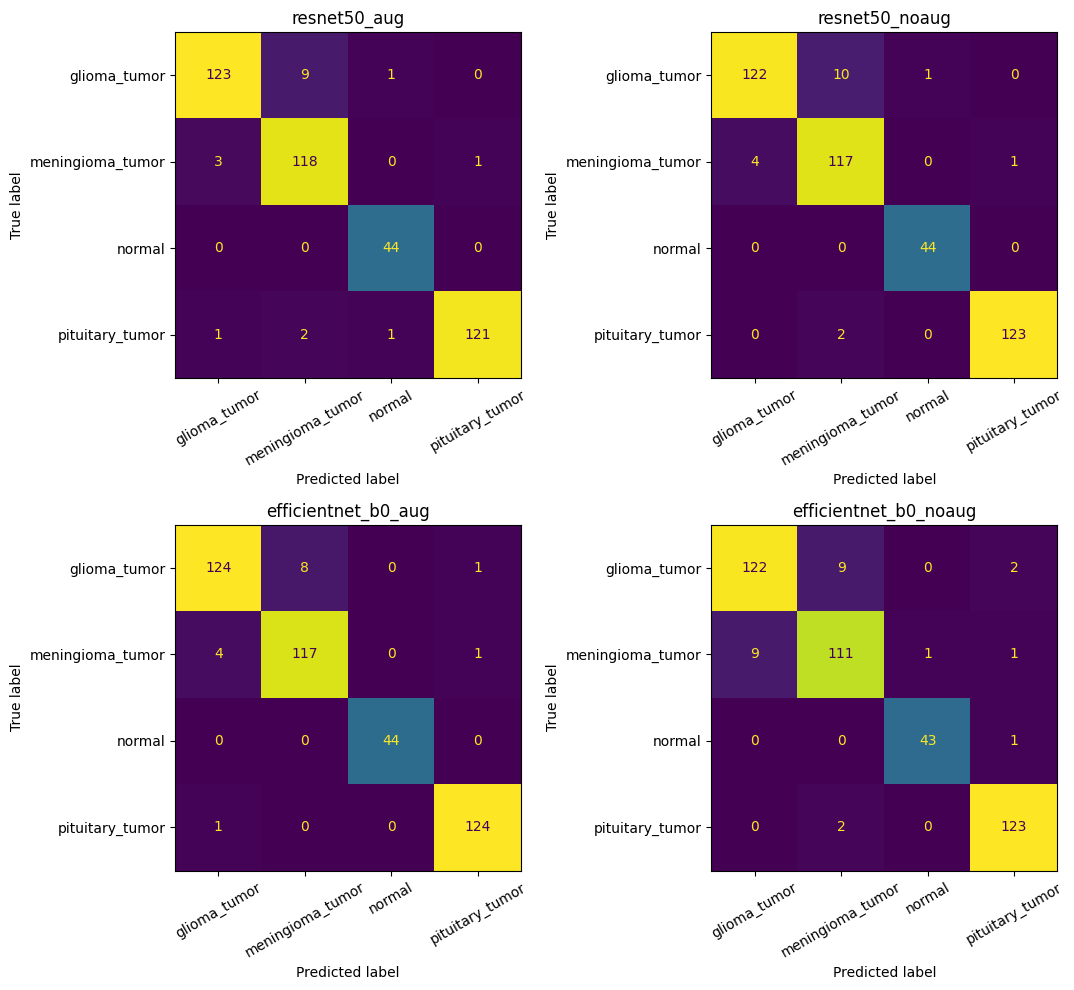

In [23]:
fig, axs = plt.subplots(2, 2, figsize=(11, 10))
for ax, (tag, r) in zip(axs.ravel(), results.items()):
    cm = confusion_matrix(r['yt'], r['yp'])
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, colorbar=False, xticks_rotation=30)
    ax.set_title(tag)
plt.tight_layout(); plt.show()

## 11. Análise qualitativa: imagens classificadas correta e incorretamente
Exemplos de acertos e erros. Para a discussão no artigo, observe em cada erro: confusão entre tipos de tumor com aparência parecida, tumor pequeno ou em região atípica, qualidade/contraste da imagem, corte da fatia ou possível erro de rótulo.

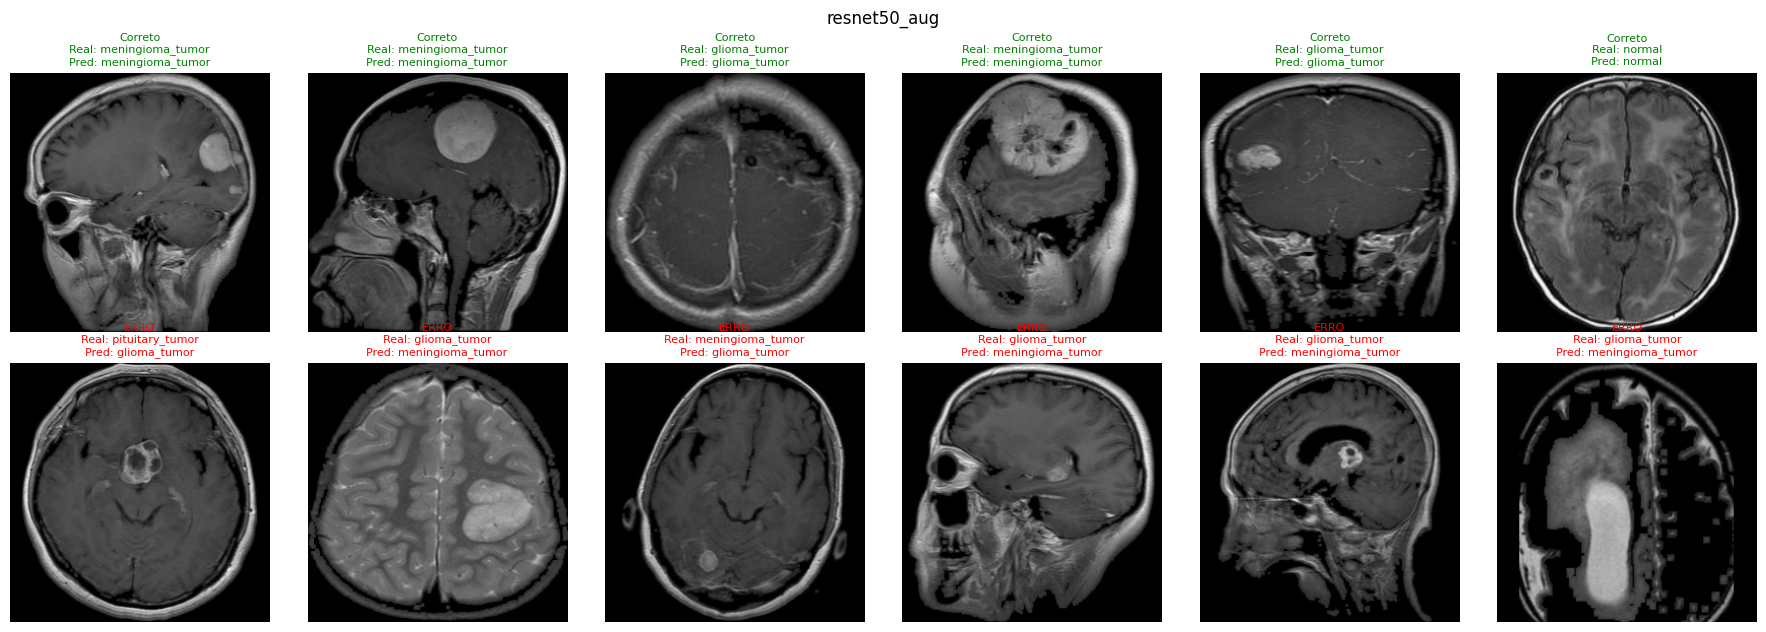

resnet50_aug: 18 erros em 424 imagens de teste


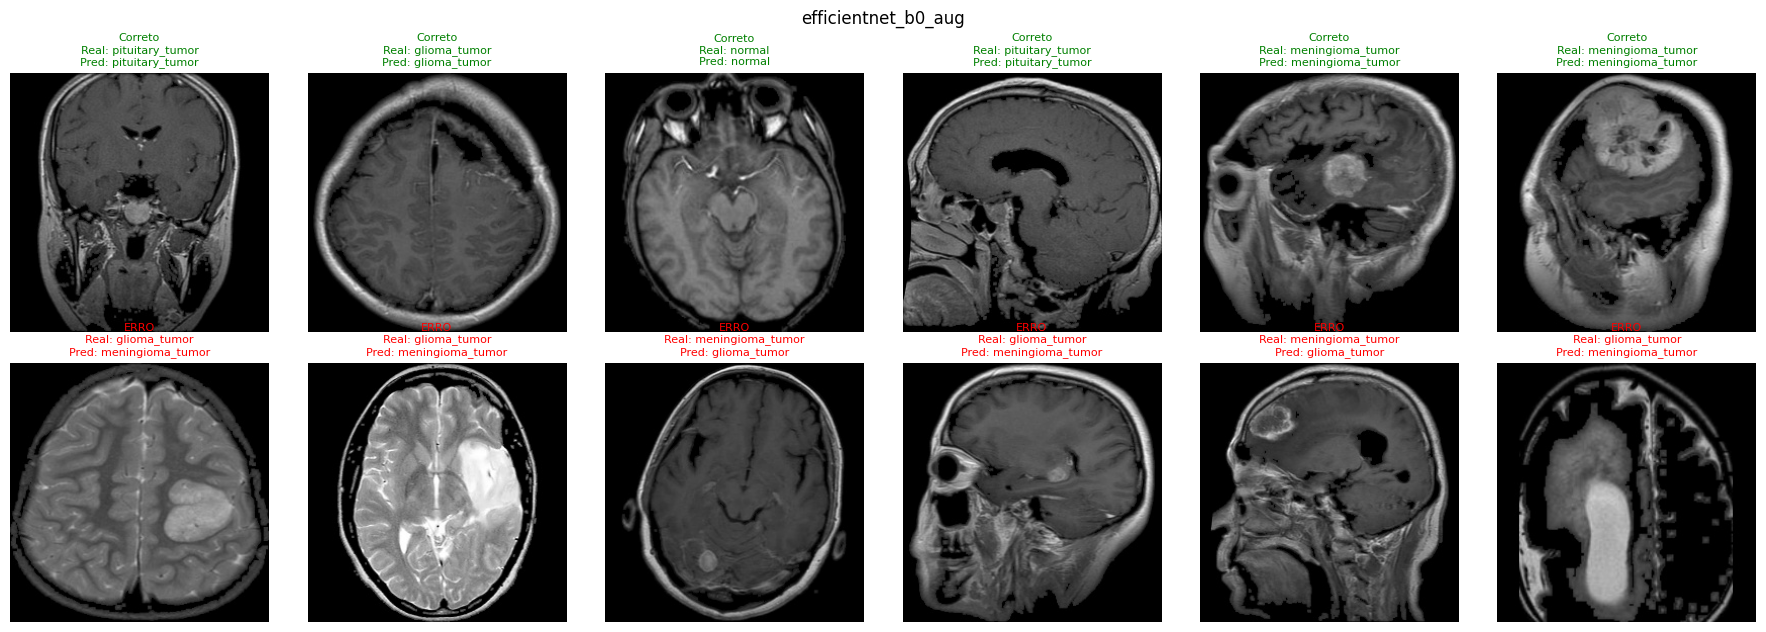

efficientnet_b0_aug: 15 erros em 424 imagens de teste


In [24]:
def show_examples(tag, n=6):
    r = results[tag]; yt, yp = r['yt'], r['yp']
    test_paths = r['test_ds'].paths
    wrong = np.where(yt != yp)[0]; right = np.where(yt == yp)[0]
    rng = np.random.RandomState(SEED)
    sel = [('Correto', i) for i in rng.choice(right, min(n, len(right)), replace=False)] + \
          [('ERRO', i)    for i in wrong[:n]]
    cols = n
    rows = int(np.ceil(len(sel) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(3*cols, 3.2*rows))
    for a in np.ravel(axs): a.axis('off')
    for a, (k, i) in zip(np.ravel(axs), sel):
        a.imshow(Image.open(test_paths[i]).convert('RGB'))
        a.set_title(f'{k}\nReal: {class_names[yt[i]]}\nPred: {class_names[yp[i]]}', fontsize=8,
                    color='green' if k == 'Correto' else 'red')
    plt.suptitle(tag); plt.tight_layout(); plt.show()
    print(f'{tag}: {len(wrong)} erros em {len(yt)} imagens de teste')

show_examples('resnet50_aug')
show_examples('efficientnet_b0_aug')